# 16: How cheap must muons get, and what would make them that cheap?

Notebooks 09–10 found muon-catalysed d–t fusion (μCF) ~9× from net electricity and, as a neutron source, about equal to spallation today. Both verdicts hinge on the **beam energy spent per muon stopped in the fuel**, E_μ (≈5 GeV today; ~2 GeV in Kelly et al.'s 2021 design). This notebook turns the question around:

1. What E_μ does each goal require: net electricity (gain 1), a power plant (gain 4), and beating spallation as a neutron source?
2. How much does **recovering the beam heat** help? Most of the proton beam's energy ends as heat in the pion-production target, which a thermal cycle can recover.
3. What production efficiency does each target imply? With $E_\mu = 1/(Y\,\varepsilon)$, $Y$ = π⁻ produced per GeV of beam and $\varepsilon$ = capture × decay-to-μ × stopping. How does that compare with the hard floor that every π⁻ costs at least its rest mass (139.6 MeV)?

**Inputs.** The cycle model and efficiencies come from notebook 09: X = 150 fusions per muon today; η_th 0.4, η_acc 0.4; 22.4 MeV thermal per fusion with a ⁶Li blanket. Spallation gives 27.5 n/GeV (notebook 10). Muon cost and cycle scenarios, with their status:
* **E_μ ≈ 5 GeV** per muon today: stated in Parisi & Rutkowski, arXiv:2511.20951 (2025), and Yin, Kou & Chen, arXiv:2605.26432 (2026), citing Jändel, J. Fusion Energy 8, 81 (1989). Read in full text; secondary to Jändel.
* **E_μ ≈ 2 GeV**: Kelly, Hart & Rose, J. Phys. Energy 3, 035003 (2021), 2.5× below current values. Abstract level. This reduction **already includes** recovering the kinetic energy of waste particles and tritium-breeding heat, so beam-heat recovery must not be added on top of it.
* **E_μ ≈ 3.0 GeV**: active-target muon source, simulated (Newburg, ARPA-E presentation 2025, cited by Parisi & Rutkowski). Secondary; not demonstrated. Whether it includes energy recovery is not stated.
* **Fusions per muon X**, from Yin et al. (2026) Table I: 148 unpolarised, 193 polarised (conservative), 292 (optimistic), 300–350 ("multi-technology synergy"; the authors consider scenarios up to this column to have experimental support or a clear technical route), 500–600 (engineering limit, extrapolative). Notebook 09's lever case, X = 336, lies inside the synergy range.
* **Beam-heat recovery** f_heat = 0.8 of the beam energy: an assumption.

In [1]:
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,"font.size":10})
BLUE, ORANGE, AQUA, MAGENTA, INK, MUTED = "#2a78d6","#eb6834","#1baf7a","#e87ba4","#0b0b0b","#52514e"
E_TH = 22.4e-3            # GeV thermal per d-t fusion with 6Li blanket
SPALL = 27.5              # n/GeV
M_PI = 0.1396             # GeV, pi- rest mass: hard floor on beam energy per pion
def gain(X, Emu, eta_th=0.4, eta_acc=0.4, f_heat=0.0):
    # electricity out / wall-plug electricity in; recovered beam heat adds eta_th * f_heat * Emu
    return eta_th*(X*E_TH + f_heat*Emu)/(Emu/eta_acc)
def Emu_for(G, X, eta_th=0.4, eta_acc=0.4, f_heat=0.0):
    # solve eta_th*eta_acc*(X E_TH + f Emu) = G Emu
    den = G - eta_th*eta_acc*f_heat
    return np.where(den > 0, eta_th*eta_acc*X*E_TH/den, np.inf)
print(f"check vs notebook 09: X=150, 5 GeV -> gain {gain(150, 5.0):.2f} (nb09: 0.11); "
      f"X=336, 2 GeV, eta 0.5/0.6 -> {gain(336, 2.0, 0.5, 0.6):.2f} (nb09: 1.13)")

check vs notebook 09: X=150, 5 GeV -> gain 0.11 (nb09: 0.11); X=336, 2 GeV, eta 0.5/0.6 -> 1.13 (nb09: 1.13)


In [2]:
CASES = [("today's cycle (X=150), η 0.4/0.4", 150, 0.4, 0.4), ("levers (X=336), η 0.4/0.4", 336, 0.4, 0.4),
         ("levers (X=336), η 0.5/0.6", 336, 0.5, 0.6)]
print(f"{'case':36s} {'heat rec.':>9s} {'E_mu for gain 1':>16s} {'gain 4':>8s}   (GeV of beam per stopped muon)")
for name, X, et, ea in CASES:
    for f in [0.0, 0.8]:
        print(f"{name:36s} {f:9.1f} {float(Emu_for(1, X, et, ea, f)):16.2f} {float(Emu_for(4, X, et, ea, f)):8.2f}")
print(f"\nneutron source: beats spallation when X/E_mu > {SPALL} n/GeV -> E_mu < {150/SPALL:.1f} GeV (X=150), < {336/SPALL:.1f} GeV (X=336)")

case                                 heat rec.  E_mu for gain 1   gain 4   (GeV of beam per stopped muon)
today's cycle (X=150), η 0.4/0.4           0.0             0.54     0.13
today's cycle (X=150), η 0.4/0.4           0.8             0.62     0.14
levers (X=336), η 0.4/0.4                  0.0             1.20     0.30
levers (X=336), η 0.4/0.4                  0.8             1.38     0.31
levers (X=336), η 0.5/0.6                  0.0             2.26     0.56
levers (X=336), η 0.5/0.6                  0.8             2.97     0.60

neutron source: beats spallation when X/E_mu > 27.5 n/GeV -> E_mu < 5.5 GeV (X=150), < 12.2 GeV (X=336)


In [3]:
SOURCES = [("5 GeV (today)", 5.0, 0.0), ("5 GeV + beam-heat recovery", 5.0, 0.8),
           ("3.0 GeV active target (no recovery)", 3.0, 0.0), ("3.0 GeV active target + recovery", 3.0, 0.8),
           ("2 GeV Kelly et al. (recovery included)", 2.0, 0.0)]
XS = [("148 unpolarised", 148), ("193 polarised", 193), ("292 optimistic", 292), ("325 synergy", 325), ("550 eng. limit", 550)]
for et, ea in [(0.4, 0.4), (0.5, 0.6)]:
    print(f"electrical gain, η_th {et}, η_acc {ea}")
    print(f"   {'muon source':40s}" + "".join(f"{x[0]:>17s}" for x in XS))
    for name, E, f in SOURCES:
        print(f"   {name:40s}" + "".join(f"{gain(X, E, et, ea, f):17.2f}" for _, X in XS))
print(f"neutron source: beats spallation when E_mu < X/{SPALL}: " + ", ".join(f"X={X}: {X/SPALL:.1f} GeV" for _, X in XS))

electrical gain, η_th 0.4, η_acc 0.4
   muon source                               148 unpolarised    193 polarised   292 optimistic      325 synergy   550 eng. limit
   5 GeV (today)                                        0.11             0.14             0.21             0.23             0.39
   5 GeV + beam-heat recovery                           0.23             0.27             0.34             0.36             0.52
   3.0 GeV active target (no recovery)                  0.18             0.23             0.35             0.39             0.66
   3.0 GeV active target + recovery                     0.30             0.36             0.48             0.52             0.79
   2 GeV Kelly et al. (recovery included)               0.27             0.35             0.52             0.58             0.99
electrical gain, η_th 0.5, η_acc 0.6
   muon source                               148 unpolarised    193 polarised   292 optimistic      325 synergy   550 eng. limit
   5 GeV (today)       

In [4]:
print("required production efficiency Y·ε (stopped muons per GeV of beam) = 1/E_mu, vs the rest-mass floor")
print(f"   rest-mass floor: at most {1/M_PI:.1f} π⁻ per GeV even if all beam energy became π⁻ rest mass")
targets = [("today (Jändel 1989, via 2025–26 reviews)", 5.0), ("Kelly et al. 2021 (2.5× below today)", 2.0), ("beat spallation, X=150", 150/SPALL),
           ("net electricity, X=150, η .4/.4, heat rec.", float(Emu_for(1, 150, f_heat=0.8))),
           ("net electricity, X=336, η .4/.4, heat rec.", float(Emu_for(1, 336, f_heat=0.8))),
           ("gain 4, X=336, η .5/.6, heat rec.", float(Emu_for(4, 336, 0.5, 0.6, 0.8)))]
for name, E in targets:
    print(f"   {name:44s} E_mu = {E:5.2f} GeV -> Y·ε ≥ {1/E:5.2f} /GeV = {100*M_PI/E:5.1f}% of the rest-mass floor")

required production efficiency Y·ε (stopped muons per GeV of beam) = 1/E_mu, vs the rest-mass floor
   rest-mass floor: at most 7.2 π⁻ per GeV even if all beam energy became π⁻ rest mass
   today (Jändel 1989, via 2025–26 reviews)     E_mu =  5.00 GeV -> Y·ε ≥  0.20 /GeV =   2.8% of the rest-mass floor
   Kelly et al. 2021 (2.5× below today)         E_mu =  2.00 GeV -> Y·ε ≥  0.50 /GeV =   7.0% of the rest-mass floor
   beat spallation, X=150                       E_mu =  5.45 GeV -> Y·ε ≥  0.18 /GeV =   2.6% of the rest-mass floor
   net electricity, X=150, η .4/.4, heat rec.   E_mu =  0.62 GeV -> Y·ε ≥  1.62 /GeV =  22.6% of the rest-mass floor
   net electricity, X=336, η .4/.4, heat rec.   E_mu =  1.38 GeV -> Y·ε ≥  0.72 /GeV =  10.1% of the rest-mass floor
   gain 4, X=336, η .5/.6, heat rec.            E_mu =  0.60 GeV -> Y·ε ≥  1.67 /GeV =  23.2% of the rest-mass floor


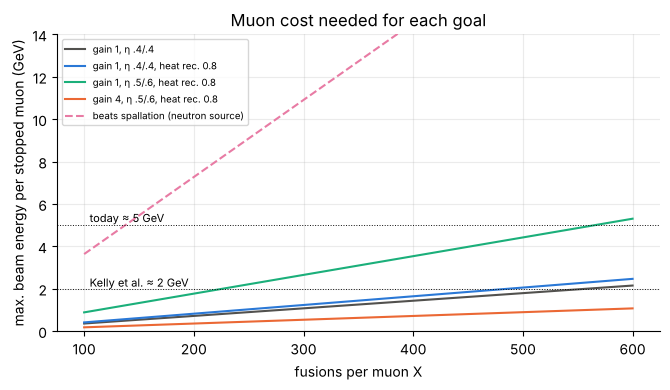

In [5]:
fig, ax = plt.subplots(figsize=(6.8, 4))
X = np.linspace(100, 600, 200)
for (lab, et, ea, f), c in zip([("gain 1, η .4/.4", .4, .4, 0), ("gain 1, η .4/.4, heat rec. 0.8", .4, .4, .8),
                                ("gain 1, η .5/.6, heat rec. 0.8", .5, .6, .8), ("gain 4, η .5/.6, heat rec. 0.8", .5, .6, .8)],
                               [MUTED, BLUE, AQUA, ORANGE]):
    G = 4 if lab.startswith("gain 4") else 1
    ax.plot(X, Emu_for(G, X, et, ea, f), color=c, label=lab)
ax.plot(X, X/SPALL, color=MAGENTA, ls="--", label="beats spallation (neutron source)")
ax.axhline(5, color=INK, lw=.7, ls=":"); ax.text(105, 5.15, "today ≈ 5 GeV", fontsize=8)
ax.axhline(2, color=INK, lw=.7, ls=":"); ax.text(105, 2.1, "Kelly et al. ≈ 2 GeV", fontsize=8)
ax.scatter([150, 336], [0, 0], s=0)
ax.set_xlabel("fusions per muon X"); ax.set_ylabel("max. beam energy per stopped muon (GeV)"); ax.set_ylim(0, 14)
ax.legend(fontsize=7, loc="upper left"); ax.set_title("Muon cost needed for each goal")
plt.tight_layout(); plt.savefig("../figures/16_muon_cost_targets.png", dpi=160); plt.show()

## Interpretation

Numbers from the printed results above. Status of each input is in the header.

1. **Net electricity with today's cycle (X ≈ 150) needs 0.54–0.62 GeV per muon**, 8–9× cheaper than today and 23% of the rest-mass ceiling. Cheaper muons alone are not a realistic route.
2. **At today's conversion efficiencies (η 0.4/0.4), no scenario reaches net electricity.** The best within the "synergy" range that Yin et al. consider technically supported is a 2 GeV source at X ≈ 325, giving gain 0.58. Even the extrapolated engineering-limit cycle only reaches 0.99.
3. **Better conversion (η_th 0.5, η_acc 0.6) is the deciding factor.** With it, a 2 GeV source (Kelly et al.) at X ≈ 325 reaches **gain 1.09**, and a 3.0 GeV active target with beam-heat recovery reaches 0.97. Both are at the threshold, not beyond it. Clear margin needs the extrapolated engineering-limit cycle (X ≈ 550): 1.85 with a 2 GeV source, 1.47 with a 3.0 GeV active target plus recovery.
4. **Beam-heat recovery** raises a present-day 5 GeV source from 0.11 to 0.23 (η 0.4/0.4). It is one of the ingredients of Kelly et al.'s 2.5× reduction, not an extra lever on top of it. The first version of this notebook combined the two and double-counted; that is corrected here.
5. **As a neutron source, μCF ties spallation today** (break-even at 5.4 GeV per muon vs ~5). With polarised fuel (X ≈ 193) it wins at any muon cost below 7.0 GeV, and with the synergy cycle below 11.8 GeV. For waste burning and isotopes, the cycle measurements (polarisation, sticking, cycling; MuFusE at PSI, J-PARC) matter more than muon cost.
6. **A power plant (gain 4)** needs ≤0.6 GeV per muon even with every lever. It is out of reach.

**Bottom line:** with sourced inputs, muon-catalysed fusion reaches net electricity only at the edge. It needs a 2–3 GeV muon source, the full synergy cycle *and* 50%/60% conversion efficiencies, all together. Its clearer near-term role is as a neutron source for waste burning and isotope production, where it already ties spallation and would win with polarised fuel.